# Student Performance Analysis – Sample Data Analyst Project
**Audience:** B.Tech 1st Year students (Data Analyst track) | **Tools:** Python, pandas, matplotlib, seaborn

## 1. Business problem
The college wants to understand **what drives first-semester marks** so that mentors can support at-risk students early.

**Questions we will answer**
1. What is the overall performance of the batch?
2. Do attendance and study hours affect marks?
3. Does performance differ by branch, gender, residence or tutoring?
4. Which students are at risk (average marks below 50)?

> The dataset is **synthetic** (computer-generated) and contains no real student data.

## 2. Import libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style='whitegrid')
plt.rcParams['figure.dpi']=100

## 3. Load and inspect the data

In [2]:
df = pd.read_csv('../data/raw/student_performance.csv')
print('Rows, Columns:', df.shape)
df.head()

Rows, Columns: (255, 11)


,Student_ID,Gender,Branch,Residence,Attendance_Pct,Study_Hours_Per_Week,Sleep_Hours,Tutoring,Maths_Marks,Physics_Marks,Programming_Marks
0,S1001,Female,ME,Day Scholar,74.8,10.6,6.8,Yes,62.0,60.0,73.0
1,S1002,Female,IT,Day Scholar,89.5,11.5,8.1,Yes,72.0,68.0,80.0
2,S1003,Male,CE,Day Scholar,48.6,13.1,7.2,No,55.0,39.0,52.0
3,S1004,Male,ECE,Day Scholar,58.0,15.1,7.6,No,65.0,65.0,66.0
4,S1005,Male,CSE,Day Scholar,64.9,7.0,5.9,No,47.0,42.0,48.0


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 255 entries, 0 to 254
Data columns (total 11 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Student_ID            255 non-null    str    
 1   Gender                255 non-null    str    
 2   Branch                255 non-null    str    
 3   Residence             255 non-null    str    
 4   Attendance_Pct        249 non-null    float64
 5   Study_Hours_Per_Week  249 non-null    float64
 6   Sleep_Hours           251 non-null    float64
 7   Tutoring              255 non-null    str    
 8   Maths_Marks           251 non-null    float64
 9   Physics_Marks         255 non-null    float64
 10  Programming_Marks     255 non-null    float64
dtypes: float64(6), str(5)
memory usage: 22.0 KB


In [4]:
print('Missing values per column:'); print(df.isna().sum()[df.isna().sum()>0])
print('\nDuplicate rows:', df.duplicated().sum())
df.describe().round(1)

Missing values per column:
Attendance_Pct          6
Study_Hours_Per_Week    6
Sleep_Hours             4
Maths_Marks             4
dtype: int64

Duplicate rows: 5


,Attendance_Pct,Study_Hours_Per_Week,Sleep_Hours,Maths_Marks,Physics_Marks,Programming_Marks
count,249.0,249.0,251.0,251.0,255.0,255.0
mean,75.6,12.0,6.8,64.5,62.0,66.8
std,12.1,4.8,1.1,9.7,10.6,9.9
min,40.0,1.0,4.0,36.0,36.0,41.0
25%,67.9,8.7,6.2,58.0,54.5,59.5
50%,76.4,12.0,6.9,64.0,62.0,67.0
75%,82.4,15.1,7.6,71.0,69.5,73.0
max,105.0,26.0,9.0,94.0,86.0,91.0


**What we found:** some missing values, duplicate rows, inconsistent text in `Gender` (e.g. `male`, `FEMALE`) and an impossible attendance value above 100. We clean these next.

## 4. Clean the data

In [5]:
clean = df.copy()
# 1. Remove duplicate rows
clean = clean.drop_duplicates()
# 2. Standardise text
clean['Gender'] = clean['Gender'].str.strip().str.title()
# 3. Fix impossible values (attendance cannot exceed 100)
clean.loc[clean['Attendance_Pct']>100,'Attendance_Pct'] = np.nan
# 4. Fill missing numbers with the median (robust to outliers)
num_cols = ['Attendance_Pct','Study_Hours_Per_Week','Sleep_Hours','Maths_Marks','Physics_Marks','Programming_Marks']
for c in num_cols:
    clean[c] = clean[c].fillna(clean[c].median())
print('Rows after cleaning:', len(clean), '| Missing values left:', clean.isna().sum().sum())

Rows after cleaning: 250 | Missing values left: 0


## 5. Create new columns (feature engineering)

In [6]:
clean['Average_Marks'] = clean[['Maths_Marks','Physics_Marks','Programming_Marks']].mean(axis=1).round(1)
def grade(m):
    if m>=75: return 'Distinction'
    if m>=60: return 'First Class'
    if m>=50: return 'Pass'
    return 'At Risk'
clean['Result_Band'] = clean['Average_Marks'].apply(grade)
clean['Attendance_Band'] = pd.cut(clean['Attendance_Pct'],[0,60,75,90,100],labels=['<60%','60-75%','75-90%','>90%'])
clean[['Student_ID','Average_Marks','Result_Band','Attendance_Band']].head()

,Student_ID,Average_Marks,Result_Band,Attendance_Band
0,S1001,65.0,First Class,60-75%
1,S1002,73.3,First Class,75-90%
2,S1003,48.7,At Risk,<60%
3,S1004,65.3,First Class,<60%
4,S1005,45.7,At Risk,60-75%


## 6. Exploratory data analysis (EDA)

### Q1. Overall performance

count    250.0
mean      64.4
std        8.7
min       42.3
25%       58.0
50%       65.0
75%       70.7
max       86.7
Name: Average_Marks, dtype: float64


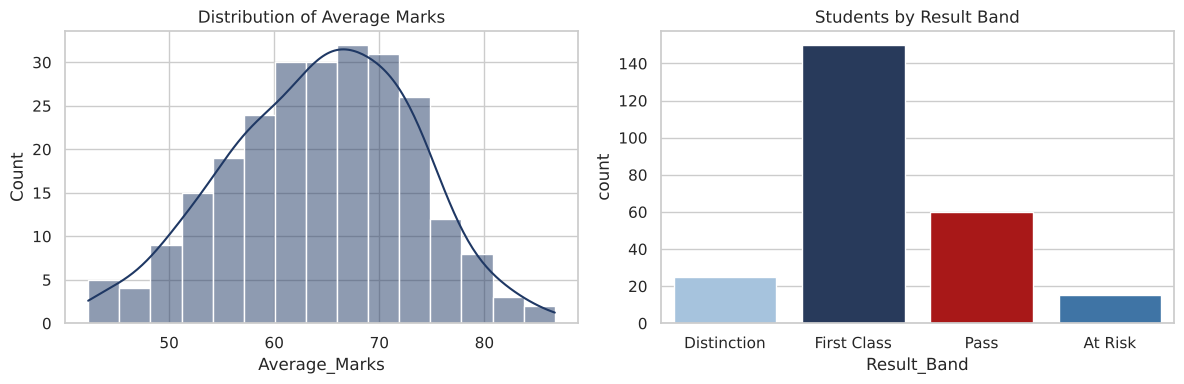

In [7]:
print(clean['Average_Marks'].describe().round(1))
fig,ax=plt.subplots(1,2,figsize=(12,4))
sns.histplot(clean['Average_Marks'],bins=15,kde=True,color='#1F3864',ax=ax[0]);ax[0].set_title('Distribution of Average Marks')
order=['Distinction','First Class','Pass','At Risk']
sns.countplot(data=clean,x='Result_Band',hue='Result_Band',legend=False,order=order,palette=['#1F3864','#2E75B6','#9DC3E6','#C00000'],ax=ax[1]);ax[1].set_title('Students by Result Band')
plt.tight_layout();plt.savefig('../images/01_overall_performance.png');plt.show()

### Q2. Do attendance and study hours affect marks?

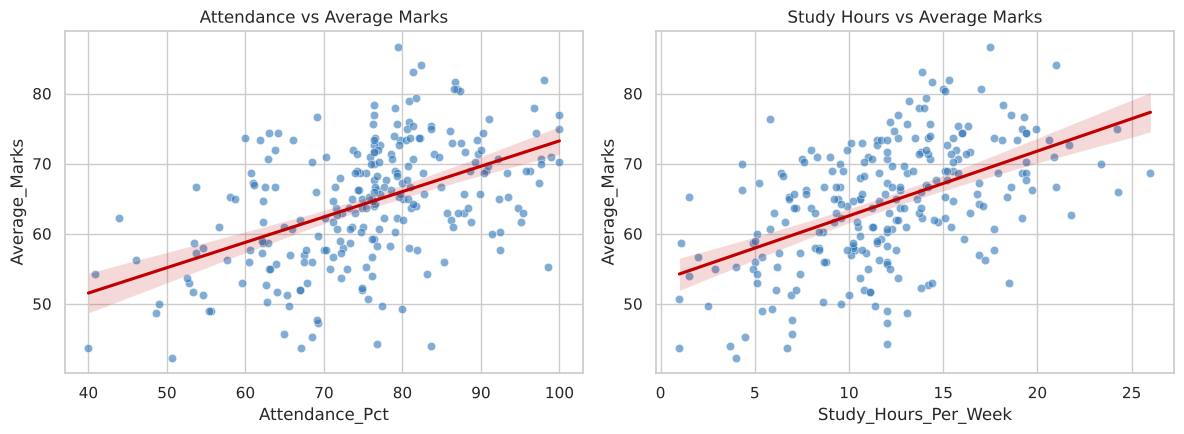

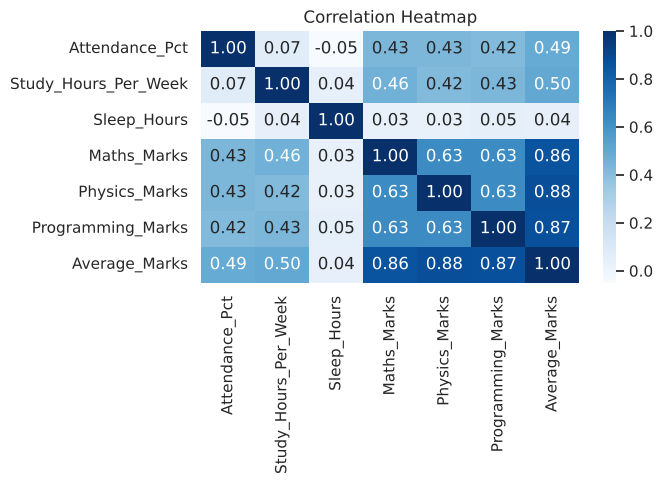

In [8]:
fig,ax=plt.subplots(1,2,figsize=(12,4.5))
sns.scatterplot(data=clean,x='Attendance_Pct',y='Average_Marks',alpha=.6,color='#2E75B6',ax=ax[0])
sns.regplot(data=clean,x='Attendance_Pct',y='Average_Marks',scatter=False,color='#C00000',ax=ax[0]);ax[0].set_title('Attendance vs Average Marks')
sns.scatterplot(data=clean,x='Study_Hours_Per_Week',y='Average_Marks',alpha=.6,color='#2E75B6',ax=ax[1])
sns.regplot(data=clean,x='Study_Hours_Per_Week',y='Average_Marks',scatter=False,color='#C00000',ax=ax[1]);ax[1].set_title('Study Hours vs Average Marks')
plt.tight_layout();plt.savefig('../images/02_attendance_study.png');plt.show()
plt.figure(figsize=(7,5))
sns.heatmap(clean[num_cols+['Average_Marks']].corr().round(2),annot=True,cmap='Blues',fmt='.2f');plt.title('Correlation Heatmap')
plt.tight_layout();plt.savefig('../images/03_correlation.png');plt.show()

In [9]:
print(clean.groupby('Attendance_Band',observed=True)['Average_Marks'].agg(['count','mean']).round(1))

                 count  mean
Attendance_Band             
<60%                23  55.7
60-75%              85  60.7
75-90%             114  67.8
>90%                28  68.7


### Q3. Does performance differ by branch, gender, residence or tutoring?

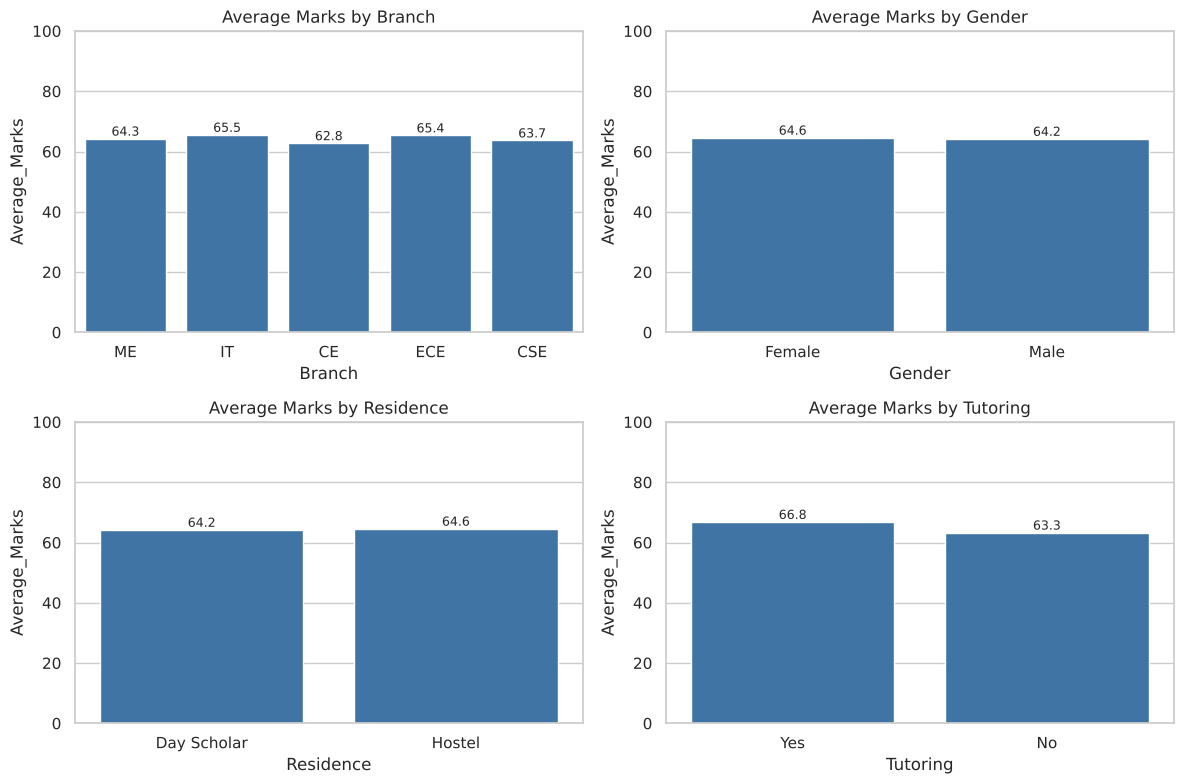

In [10]:
fig,ax=plt.subplots(2,2,figsize=(12,8))
for a,col in zip(ax.flat,['Branch','Gender','Residence','Tutoring']):
    sns.barplot(data=clean,x=col,y='Average_Marks',errorbar=None,color='#2E75B6',ax=a)
    a.set_title(f'Average Marks by {col}');a.set_ylim(0,100)
    for p in a.patches:a.annotate(f'{p.get_height():.1f}',(p.get_x()+p.get_width()/2,p.get_height()),ha='center',va='bottom',fontsize=9)
plt.tight_layout();plt.savefig('../images/04_group_comparison.png');plt.show()

### Q4. Which students are at risk?

In [11]:
risk = clean[clean['Result_Band']=='At Risk'].sort_values('Average_Marks')
print(f'{len(risk)} students ({len(risk)/len(clean):.1%}) are At Risk')
print('Average attendance of At Risk students:', round(risk['Attendance_Pct'].mean(),1),'% vs overall', round(clean['Attendance_Pct'].mean(),1),'%')
risk[['Student_ID','Branch','Attendance_Pct','Study_Hours_Per_Week','Average_Marks']].head(10)

15 students (6.0%) are At Risk
Average attendance of At Risk students: 64.8 % vs overall 75.5 %


,Student_ID,Branch,Attendance_Pct,Study_Hours_Per_Week,Average_Marks
103,S1104,CE,50.6,4.0,42.3
247,S1248,IT,67.1,1.0,43.7
229,S1230,CSE,40.0,6.7,43.7
43,S1044,IT,83.6,3.7,44.0
188,S1189,ME,76.8,12.0,44.3
193,S1194,ME,68.5,4.5,45.3
4,S1005,CSE,64.9,7.0,45.7
171,S1172,ECE,69.3,12.0,47.3
203,S1204,CSE,69.1,7.0,47.7
2,S1003,CE,48.6,13.1,48.7


## 7. Key insights (generated from the data)

In [12]:
r_att=clean['Attendance_Pct'].corr(clean['Average_Marks']);r_st=clean['Study_Hours_Per_Week'].corr(clean['Average_Marks'])
best=clean.groupby('Branch')['Average_Marks'].mean().idxmax();worst=clean.groupby('Branch')['Average_Marks'].mean().idxmin()
tut=clean.groupby('Tutoring')['Average_Marks'].mean()
print(f"1. Batch average marks: {clean['Average_Marks'].mean():.1f}; median {clean['Average_Marks'].median():.1f}.")
print(f"2. Attendance vs marks correlation = {r_att:.2f}; study hours vs marks = {r_st:.2f} (both positive).")
print(f"3. Highest-scoring branch: {best}; lowest: {worst}.")
print(f"4. Students with tutoring average {tut['Yes']:.1f} vs {tut['No']:.1f} without.")
print(f"5. {len(risk)} students are At Risk; their average attendance is {risk['Attendance_Pct'].mean():.0f}%.")

1. Batch average marks: 64.4; median 65.0.
2. Attendance vs marks correlation = 0.49; study hours vs marks = 0.50 (both positive).
3. Highest-scoring branch: IT; lowest: CE.
4. Students with tutoring average 66.8 vs 63.3 without.
5. 15 students are At Risk; their average attendance is 65%.


## 8. Recommendations
- Mentors should track **attendance weekly** and contact students falling below 75%.
- Run **study-skills sessions** encouraging a regular weekly study routine.
- Offer **remedial / tutoring support** to students flagged At Risk.

> **Remember:** correlation does not prove causation. This analysis shows association, not cause.

## 9. Save the cleaned data

In [13]:
clean.to_csv('../data/processed/student_performance_clean.csv',index=False)
print('Saved cleaned file with', len(clean), 'rows')

Saved cleaned file with 250 rows
